# **Maternal Health Risk**



**Import Libraries**

In [2]:
!pip install -q xgboost shap

In [3]:
import io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import shap

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

**Upload dataset**

In [4]:
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df_raw = pd.read_csv(io.BytesIO(uploaded[file_name]))
print(file_name, df_raw.shape)
df_raw.head()

Saving Mathernal_Risk.csv to Mathernal_Risk.csv
Mathernal_Risk.csv (6103, 11)


,Patient ID,Name,Age,Body Temperature(F),Heart rate(bpm),Systolic Blood Pressure(mm Hg),Diastolic Blood Pressure(mm Hg),BMI(kg/m 2),Blood Glucose(HbA1c),Blood Glucose(Fasting hour-mg/dl),Status
0,101,Bhavana,20,97.5,91,161,100,24.9,41,5.8,high risk
1,102,Mithila,45,97.7,99,99,94,22.1,36,5.7,high risk
2,103,Phoolan,29,98.6,84,129,87,19.0,42,6.4,mid risk
3,104,Joyonti,26,99.5,135,161,101,23.7,46,4.5,high risk
4,105,Vana,38,102.5,51,106,91,18.8,38,4.3,high risk


**Inspection**

In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6103 entries, 0 to 6102
Data columns (total 11 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Patient ID                         6103 non-null   int64  
 1   Name                               6103 non-null   object 
 2   Age                                6103 non-null   int64  
 3   Body Temperature(F)                6103 non-null   float64
 4   Heart rate(bpm)                    6103 non-null   int64  
 5   Systolic Blood Pressure(mm Hg)     6103 non-null   int64  
 6   Diastolic Blood Pressure(mm Hg)    6103 non-null   int64  
 7   BMI(kg/m 2)                        6103 non-null   float64
 8   Blood Glucose(HbA1c)               6103 non-null   int64  
 9   Blood Glucose(Fasting hour-mg/dl)  6103 non-null   float64
 10  Status                             6103 non-null   object 
dtypes: float64(3), int64(6), object(2)
memory usage: 524.6+ 

In [6]:
print("Missing values per column:\n", df_raw.isna().sum())
df_raw.describe().T

Missing values per column:
 Patient ID                           0
Name                                 0
Age                                  0
Body Temperature(F)                  0
Heart rate(bpm)                      0
Systolic Blood Pressure(mm Hg)       0
Diastolic Blood Pressure(mm Hg)      0
BMI(kg/m 2)                          0
Blood Glucose(HbA1c)                 0
Blood Glucose(Fasting hour-mg/dl)    0
Status                               0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Patient ID,6103.0,3152.000000,1761.928678,101.0,1626.5,3152.0,4677.5,6203.0
Age,6103.0,26.425037,6.390205,15.0,22.0,25.0,30.0,250.0
Body Temperature(F),6103.0,98.665574,1.590983,39.6,98.6,98.6,98.8,104.0
Heart rate(bpm),6103.0,86.100770,22.627587,45.0,72.0,80.0,91.0,150.0
Systolic Blood Pressure(mm Hg),6103.0,129.218253,17.234217,90.0,120.0,128.0,141.0,169.0
Diastolic Blood Pressure(mm Hg),6103.0,87.257578,7.793099,9.0,82.0,87.0,92.0,142.0
BMI(kg/m 2),6103.0,21.435581,2.157060,14.9,19.6,21.3,23.1,27.9
Blood Glucose(HbA1c),6103.0,37.904473,4.400272,30.0,34.0,38.0,41.0,50.0
Blood Glucose(Fasting hour-mg/dl),6103.0,5.504752,0.905327,3.5,4.8,5.7,6.0,8.9


# **Preprocessing**

**Leakage removal (identifiers and duplicates)**

In [7]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
df = df.drop(columns=["Patient ID", "Name"])

print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after leakage removal:", df.shape)

Exact duplicate rows: 1
Shape after leakage removal: (6102, 9)


**Cleaning (rename columns, fix units, encode the label)**

In [8]:
df = df.rename(columns={
    "Body Temperature(F)": "BodyTemp_F",
    "Heart rate(bpm)": "HeartRate_bpm",
    "Systolic Blood Pressure(mm Hg)": "SystolicBP",
    "Diastolic Blood Pressure(mm Hg)": "DiastolicBP",
    "BMI(kg/m 2)": "BMI",
    "Blood Glucose(HbA1c)": "HbA1c_mmol_mol",               # values 30–50 = mmol/mol
    "Blood Glucose(Fasting hour-mg/dl)": "FastingGlucose_mmol_L",  # values 3.5–8.9 = mmol/L
    "Status": "RiskLevel"})

df["RiskLevel"] = df["RiskLevel"].str.strip().str.lower()
LABEL_MAP = {"low risk": 0, "mid risk": 1, "high risk": 2}
CLASS_NAMES = ["Low", "Mid", "High"]
df["Target"] = df["RiskLevel"].map(LABEL_MAP)

print("Unmapped labels:", df["Target"].isna().sum())
print("Missing values:", df.isna().sum().sum())
df.head()

Unmapped labels: 0
Missing values: 0


,Age,BodyTemp_F,HeartRate_bpm,SystolicBP,DiastolicBP,BMI,HbA1c_mmol_mol,FastingGlucose_mmol_L,RiskLevel,Target
0,20,97.5,91,161,100,24.9,41,5.8,high risk,2
1,45,97.7,99,99,94,22.1,36,5.7,high risk,2
2,29,98.6,84,129,87,19.0,42,6.4,mid risk,1
3,26,99.5,135,161,101,23.7,46,4.5,high risk,2
4,38,102.5,51,106,91,18.8,38,4.3,high risk,2


**Drop inappropriate data**

In [9]:
rules = {
    "Age outside 10–60 years":     ~df["Age"].between(10, 60),
    "Body temp outside 95–105 °F": ~df["BodyTemp_F"].between(95, 105),
    "Diastolic BP < 50 mmHg":      df["DiastolicBP"] < 50,
    "Diastolic BP >= Systolic BP": df["DiastolicBP"] >= df["SystolicBP"],
}
for name, mask in rules.items():
    print(f"{name}: {mask.sum()} rows")

bad = pd.concat(rules.values(), axis=1).any(axis=1)
df = df[~bad].drop_duplicates().reset_index(drop=True)
print("\nClean dataset shape:", df.shape)   # expected about 6,038 rows

Age outside 10–60 years: 1 rows
Body temp outside 95–105 °F: 43 rows
Diastolic BP < 50 mmHg: 1 rows
Diastolic BP >= Systolic BP: 19 rows

Clean dataset shape: (6038, 10)


**Define features and target**

In [10]:
FEATURES = ["Age", "BodyTemp_F", "HeartRate_bpm", "SystolicBP", "DiastolicBP",
            "BMI", "HbA1c_mmol_mol", "FastingGlucose_mmol_L"]
X = df[FEATURES]
y = df["Target"]
print(X.shape, y.shape)

(6038, 8) (6038,)


# **EDA**

**Class distribution**

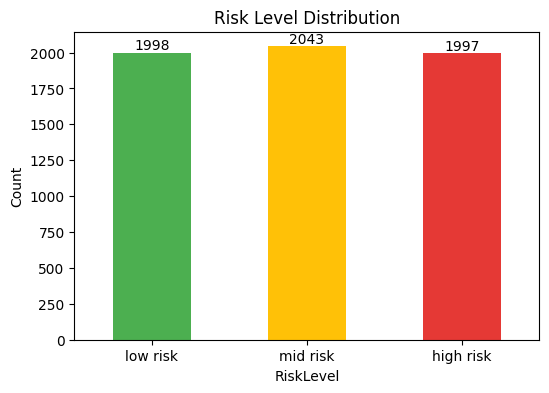

In [11]:
ax = df["RiskLevel"].value_counts().reindex(["low risk", "mid risk", "high risk"]).plot(
    kind="bar", color=["#4CAF50", "#FFC107", "#E53935"], figsize=(6, 4))
ax.bar_label(ax.containers[0])
plt.title("Risk Level Distribution"); plt.ylabel("Count"); plt.xticks(rotation=0)
plt.show()

**Feature histograms**

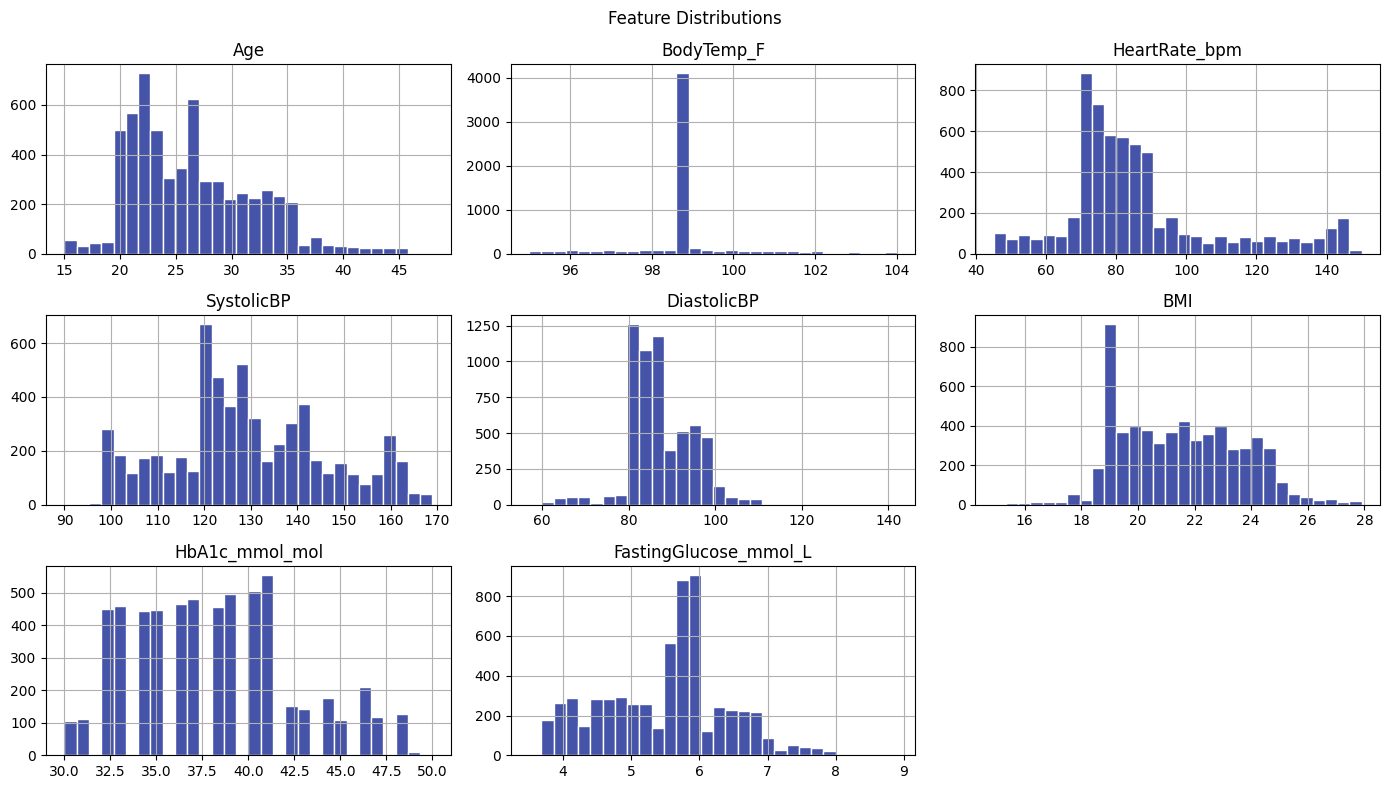

In [12]:
df[FEATURES].hist(bins=30, figsize=(14, 8), color="#4553A8", edgecolor="white")
plt.suptitle("Feature Distributions"); plt.tight_layout(); plt.show()

**Box plots by risk level**

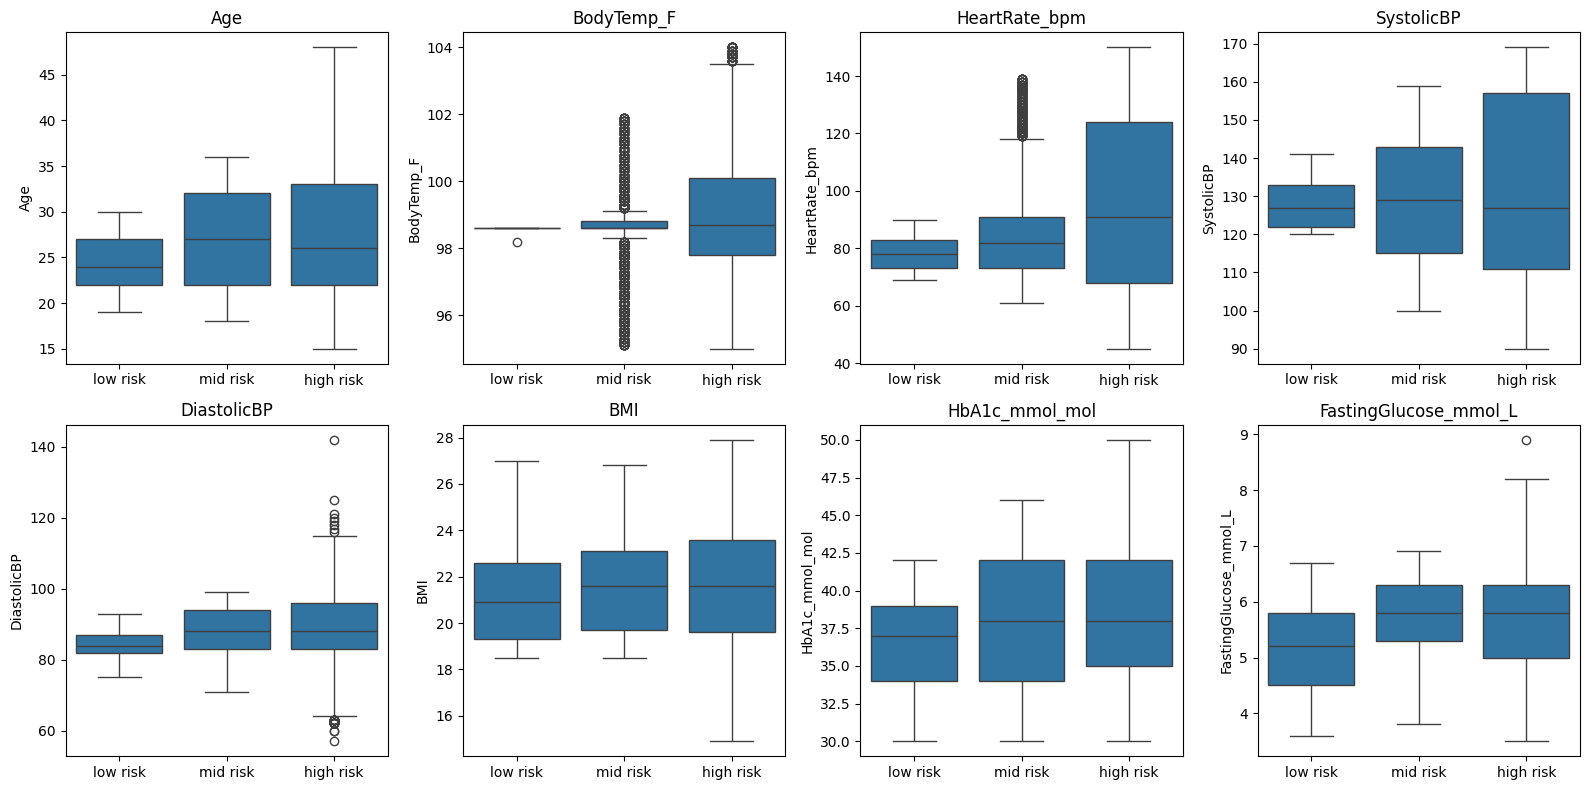

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="RiskLevel", y=col, ax=ax,
                order=["low risk", "mid risk", "high risk"])
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Correlation heatmap**

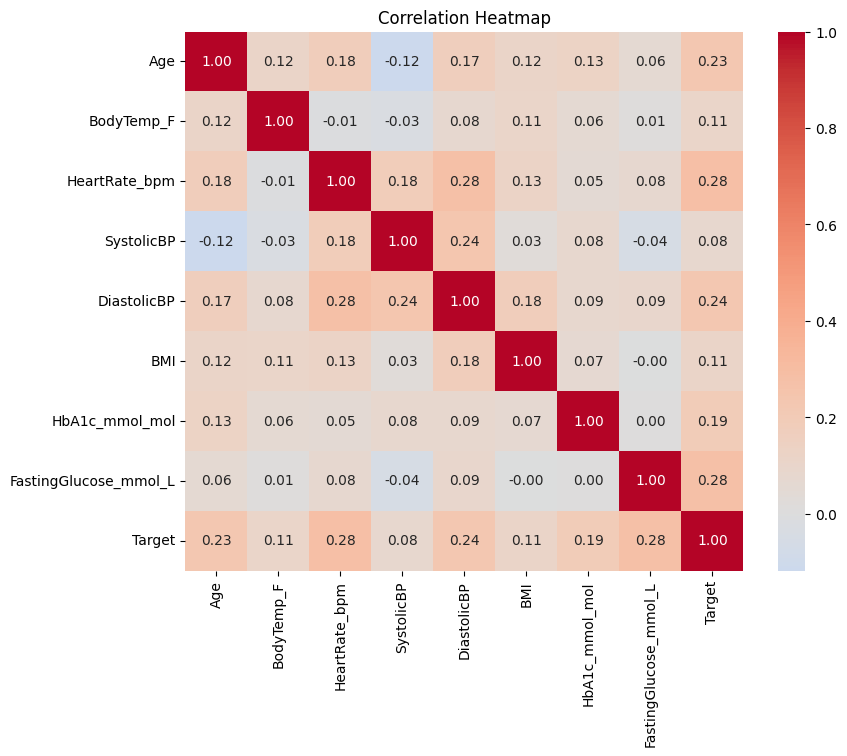

In [14]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[FEATURES + ["Target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap"); plt.show()

# **Stratified split: 70 / 15 / 15**

In [15]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")
pd.DataFrame({"Train": y_train.value_counts(normalize=True),
              "Val": y_val.value_counts(normalize=True),
              "Test": y_test.value_counts(normalize=True)}).round(3)

Train: 4226 | Validation: 906 | Test: 906


,Train,Val,Test
Target,,,
0,0.331,0.331,0.331
1,0.338,0.338,0.339
2,0.331,0.331,0.330


**Feature scaling (fitted on training data only)**

In [16]:
demo_scaler = StandardScaler().fit(X_train)
pd.DataFrame(demo_scaler.transform(X_train), columns=FEATURES).describe().T[["mean", "std"]].round(3)

,mean,std
Age,0.0,1.0
BodyTemp_F,-0.0,1.0
HeartRate_bpm,-0.0,1.0
SystolicBP,0.0,1.0
DiastolicBP,-0.0,1.0
BMI,-0.0,1.0
HbA1c_mmol_mol,0.0,1.0
FastingGlucose_mmol_L,-0.0,1.0


**Stratified 5-fold cross-validation setup**

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "precision": "precision_macro",
           "recall": "recall_macro", "f1": "f1_macro", "roc_auc": "roc_auc_ovr"}
models, cv_results = {}, {}

def train_with_cv(name, estimator, param_grid):
    pipe = Pipeline([("scaler", StandardScaler()), ("model", estimator)])
    grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    grid.fit(X_train, y_train)
    best = grid.best_estimator_
    scores = cross_validate(best, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_results[name] = {m: scores[f"test_{m}"].mean() for m in SCORING}
    cv_results[name]["f1_std"] = scores["test_f1"].std()
    models[name] = best
    print(f"{name} best params: {grid.best_params_}")
    print(f"{name} 5-fold CV macro-F1: {scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}")
    return best

# **Logistic Regression**

In [19]:
lr_best = train_with_cv(
    "Logistic Regression",
    LogisticRegression(max_iter=3000, random_state=SEED),
    {"model__C": [0.01, 0.1, 1, 10, 100]})

Logistic Regression best params: {'model__C': 0.01}
Logistic Regression 5-fold CV macro-F1: 0.5763 ± 0.0148


# **SVM**

In [20]:
svm_best = train_with_cv(
    "SVM",
    SVC(kernel="rbf", probability=True, random_state=SEED),
    {"model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1, 1]})

SVM best params: {'model__C': 10, 'model__gamma': 'scale'}
SVM 5-fold CV macro-F1: 0.9547 ± 0.0034


# **Random Forest**

In [21]:
rf_best = train_with_cv(
    "Random Forest",
    RandomForestClassifier(random_state=SEED, n_jobs=-1),
    {"model__n_estimators": [200, 400],
     "model__max_depth": [None, 10, 20],
     "model__min_samples_leaf": [1, 2]})

Random Forest best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
Random Forest 5-fold CV macro-F1: 0.9920 ± 0.0042


# **XGBoost**

In [22]:
xgb_best = train_with_cv(
    "XGBoost",
    XGBClassifier(objective="multi:softprob", eval_metric="mlogloss",
                  tree_method="hist", random_state=SEED),
    {"model__n_estimators": [200, 400],
     "model__max_depth": [3, 5, 7],
     "model__learning_rate": [0.05, 0.1],
     "model__subsample": [0.8, 1.0]})

XGBoost best params: {'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 200, 'model__subsample': 0.8}
XGBoost 5-fold CV macro-F1: 0.9924 ± 0.0036


# **Cross-validation comparison**

,accuracy,precision,recall,f1,roc_auc,f1_std
Logistic Regression,0.5833,0.5849,0.5839,0.5763,0.7393,0.0148
SVM,0.9546,0.9551,0.9546,0.9547,0.9919,0.0034
Random Forest,0.9920,0.9921,0.9919,0.9920,0.9988,0.0042
XGBoost,0.9924,0.9925,0.9924,0.9924,0.9989,0.0036


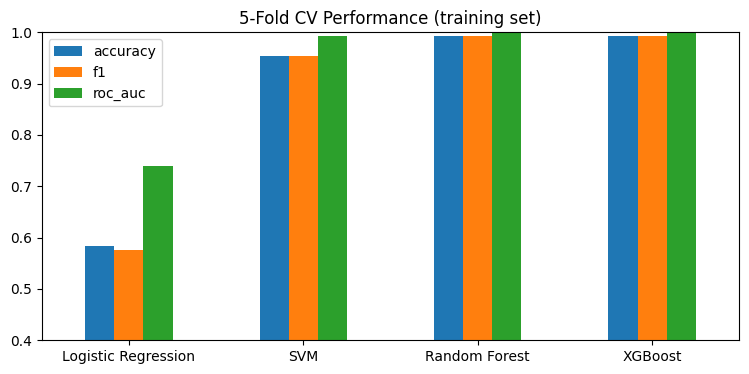

In [23]:
cv_table = pd.DataFrame(cv_results).T.round(4)
display(cv_table)

cv_table[["accuracy", "f1", "roc_auc"]].plot(kind="bar", figsize=(9, 4), ylim=(0.4, 1.0))
plt.title("5-Fold CV Performance (training set)"); plt.xticks(rotation=0); plt.show()

**Model evaluation(validation set)**

In [24]:
def evaluate(model, X_, y_, y_pred=None):
    proba = model.predict_proba(X_)
    if y_pred is None:
        y_pred = proba.argmax(axis=1)
    return {"Accuracy": accuracy_score(y_, y_pred),
            "Precision": precision_score(y_, y_pred, average="macro"),
            "Recall": recall_score(y_, y_pred, average="macro"),
            "High-risk Recall": recall_score(y_, y_pred, labels=[2], average="macro"),
            "Macro-F1": f1_score(y_, y_pred, average="macro"),
            "ROC-AUC": roc_auc_score(y_, proba, multi_class="ovr")}

val_table = pd.DataFrame({n: evaluate(m, X_val, y_val) for n, m in models.items()}).T.round(4)
val_table

,Accuracy,Precision,Recall,High-risk Recall,Macro-F1,ROC-AUC
Logistic Regression,0.5905,0.5962,0.5910,0.5000,0.5866,0.7394
SVM,0.9625,0.9632,0.9625,0.9400,0.9626,0.9908
Random Forest,0.9901,0.9902,0.9901,0.9833,0.9901,0.9986
XGBoost,0.9901,0.9903,0.9900,0.9767,0.9901,0.9985


**Confusion matrices (validation set)**

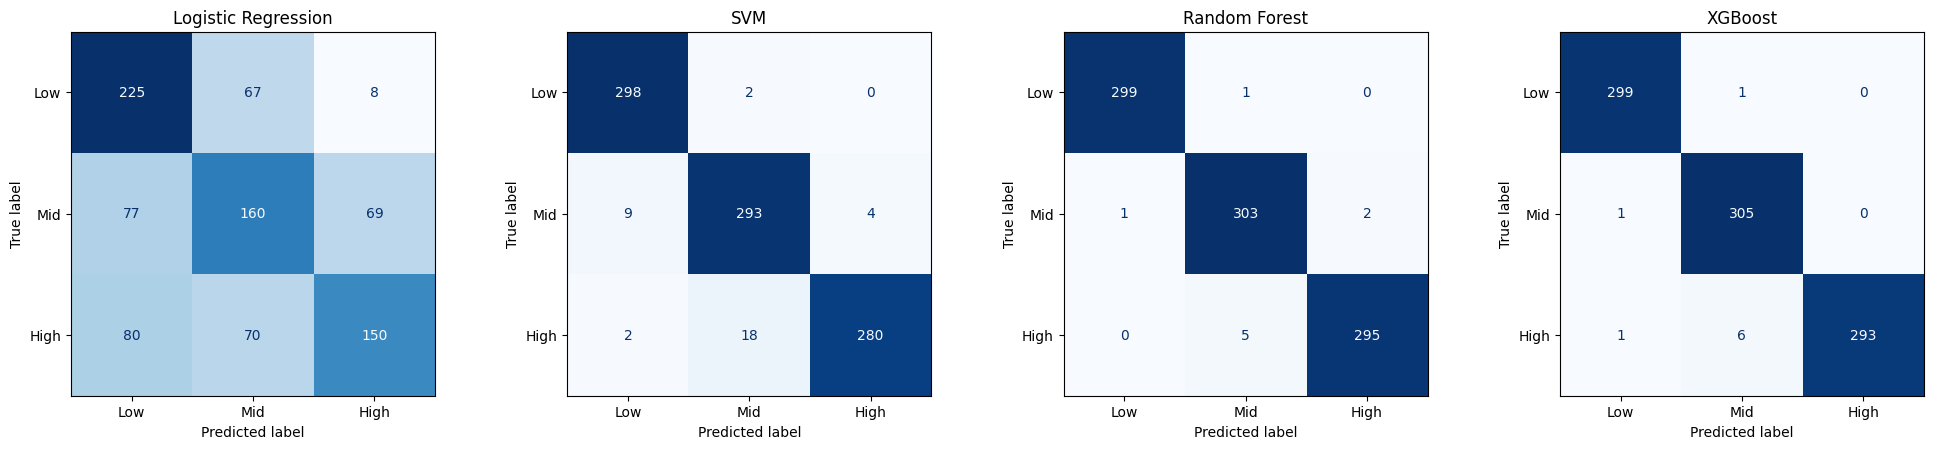

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_val, model.predict(X_val)),
                           display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

**Select the best model**

In [26]:
best_name = val_table["Macro-F1"].idxmax()
best_model = models[best_name]
print("Best model on validation set:", best_name)

Best model on validation set: Random Forest


**Probability calibration**

In [27]:
def multiclass_brier(y_true, proba):
    onehot = np.eye(proba.shape[1])[np.asarray(y_true)]
    return np.mean(np.sum((proba - onehot) ** 2, axis=1))

calibrated = CalibratedClassifierCV(estimator=clone(best_model), method="isotonic", cv=cv)
calibrated.fit(X_train, y_train)

calib_rows = {}
for label, m in [("Uncalibrated", best_model), ("Calibrated", calibrated)]:
    p = m.predict_proba(X_val)
    calib_rows[label] = {"Log loss": log_loss(y_val, p), "Brier score": multiclass_brier(y_val, p)}
calib_table = pd.DataFrame(calib_rows).T.round(4)
display(calib_table)

final_model = calibrated if calib_rows["Calibrated"]["Brier score"] < calib_rows["Uncalibrated"]["Brier score"] else best_model
print("Using:", "calibrated" if final_model is calibrated else "uncalibrated", best_name)

,Log loss,Brier score
Uncalibrated,0.0774,0.0301
Calibrated,0.1090,0.0167


Using: calibrated Random Forest


**Decision threshold**

In [28]:
def predict_with_threshold(model, X_, t):
    proba = model.predict_proba(X_)
    pred = proba.argmax(axis=1)
    pred[proba[:, 2] >= t] = 2
    return pred

rows = []
for t in np.arange(0.10, 0.65, 0.05):
    p = predict_with_threshold(final_model, X_val, t)
    rows.append({"Threshold": round(t, 2),
                 "High-risk Recall": recall_score(y_val, p, labels=[2], average="macro"),
                 "Macro-F1": f1_score(y_val, p, average="macro")})
thr_table = pd.DataFrame(rows).round(4)
display(thr_table)

ok = thr_table[thr_table["High-risk Recall"] >= 0.95]
best_t = ok.loc[ok["Macro-F1"].idxmax(), "Threshold"] if len(ok) else 0.5
print("Chosen high-risk threshold:", best_t)

,Threshold,High-risk Recall,Macro-F1
0,0.10,0.9867,0.9846
1,0.15,0.9867,0.9879
2,0.20,0.9867,0.9901
3,0.25,0.9867,0.9901
4,0.30,0.9867,0.9901
5,0.35,0.9867,0.9912
6,0.40,0.9867,0.9912
7,0.45,0.9867,0.9912
8,0.50,0.9800,0.9901
9,0.55,0.9800,0.9901


Chosen high-risk threshold: 0.35


# **Evaluate on Test**

In [29]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import learning_curve

test_results = {}

def evaluate_on_test(name):
    model = models[name]
    test_results[name] = evaluate(model, X_test, y_test)
    print(f"--- {name} (test set) ---")
    print(pd.Series(test_results[name]).round(4).to_string())
    print()
    print(classification_report(y_test, model.predict(X_test),
                                target_names=CLASS_NAMES, digits=4))

In [30]:
evaluate_on_test("Logistic Regression")

--- Logistic Regression (test set) ---
Accuracy            0.5541
Precision           0.5598
Recall              0.5544
High-risk Recall    0.4348
Macro-F1            0.5488
ROC-AUC             0.7297

              precision    recall  f1-score   support

         Low     0.5778    0.7300    0.6451       300
         Mid     0.4826    0.4984    0.4904       307
        High     0.6190    0.4348    0.5108       299

    accuracy                         0.5541       906
   macro avg     0.5598    0.5544    0.5488       906
weighted avg     0.5592    0.5541    0.5483       906



In [31]:
evaluate_on_test("SVM")

--- SVM (test set) ---
Accuracy            0.9470
Precision           0.9479
Recall              0.9471
High-risk Recall    0.9231
Macro-F1            0.9471
ROC-AUC             0.9890

              precision    recall  f1-score   support

         Low     0.9429    0.9900    0.9659       300
         Mid     0.9297    0.9479    0.9387       307
        High     0.9856    0.9164    0.9497       299

    accuracy                         0.9514       906
   macro avg     0.9527    0.9514    0.9514       906
weighted avg     0.9525    0.9514    0.9513       906



In [32]:
evaluate_on_test("Random Forest")

--- Random Forest (test set) ---
Accuracy            0.9857
Precision           0.9857
Recall              0.9857
High-risk Recall    0.9799
Macro-F1            0.9857
ROC-AUC             0.9975

              precision    recall  f1-score   support

         Low     0.9835    0.9933    0.9884       300
         Mid     0.9805    0.9837    0.9821       307
        High     0.9932    0.9799    0.9865       299

    accuracy                         0.9857       906
   macro avg     0.9857    0.9857    0.9857       906
weighted avg     0.9857    0.9857    0.9857       906



In [33]:
evaluate_on_test("XGBoost")

--- XGBoost (test set) ---
Accuracy            0.9879
Precision           0.9879
Recall              0.9879
High-risk Recall    0.9833
Macro-F1            0.9879
ROC-AUC             0.9979

              precision    recall  f1-score   support

         Low     0.9836    0.9967    0.9901       300
         Mid     0.9869    0.9837    0.9853       307
        High     0.9932    0.9833    0.9882       299

    accuracy                         0.9879       906
   macro avg     0.9879    0.9879    0.9879       906
weighted avg     0.9879    0.9879    0.9879       906



**Test-set comparison table**

,Accuracy,Precision,Recall,High-risk Recall,Macro-F1,ROC-AUC
Logistic Regression,0.5541,0.5598,0.5544,0.4348,0.5488,0.7297
SVM,0.9470,0.9479,0.9471,0.9231,0.9471,0.9890
Random Forest,0.9857,0.9857,0.9857,0.9799,0.9857,0.9975
XGBoost,0.9879,0.9879,0.9879,0.9833,0.9879,0.9979


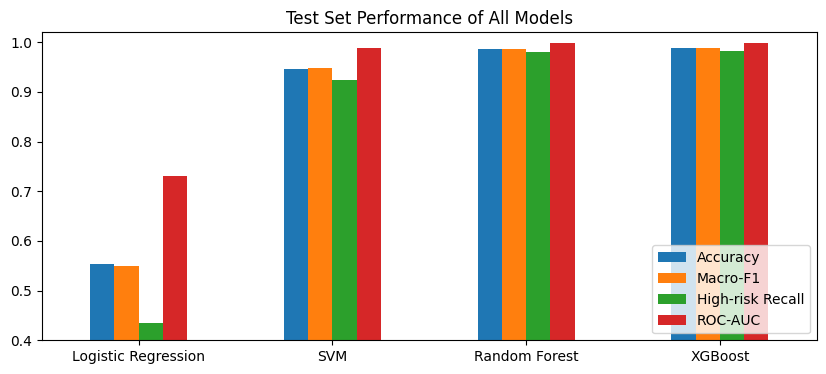

In [34]:
test_all = pd.DataFrame(test_results).T.round(4)
display(test_all)

test_all[["Accuracy", "Macro-F1", "High-risk Recall", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 4), ylim=(0.4, 1.02))
plt.title("Test Set Performance of All Models")
plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()

**Confusion matrices**

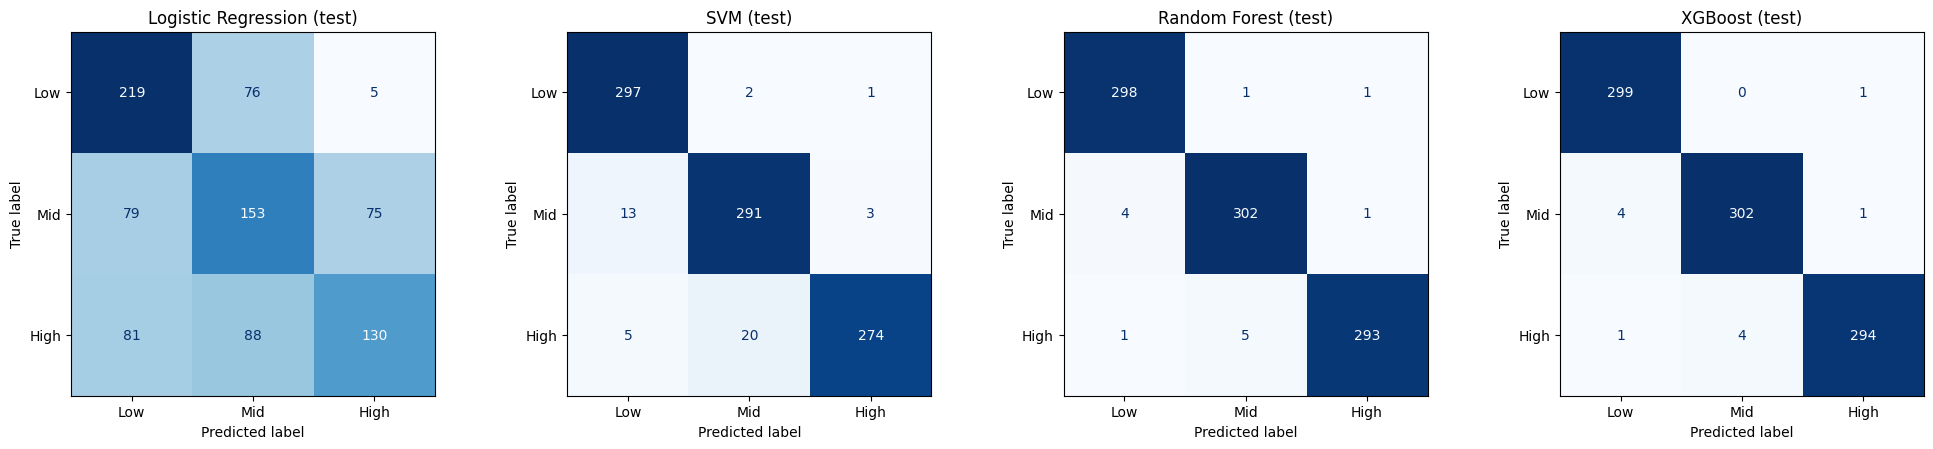

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} (test)")
plt.tight_layout(); plt.show()

# **Overfitting analysis**

In [37]:
rows = []
for name, model in models.items():
    rows.append({"Model": name,
                 "Train F1": f1_score(y_train, model.predict(X_train), average="macro"),
                 "CV F1 (mean)": cv_results[name]["f1"],
                 "CV F1 (std)": cv_results[name]["f1_std"],
                 "Validation F1": f1_score(y_val, model.predict(X_val), average="macro"),
                 "Test F1": f1_score(y_test, model.predict(X_test), average="macro")})

fit_table = pd.DataFrame(rows).set_index("Model")
fit_table["Train−CV gap"]   = fit_table["Train F1"] - fit_table["CV F1 (mean)"]
fit_table["Train−Test gap"] = fit_table["Train F1"] - fit_table["Test F1"]
fit_table["Val−Test gap"]   = fit_table["Validation F1"] - fit_table["Test F1"]
fit_table.round(4)

,Train F1,CV F1 (mean),CV F1 (std),Validation F1,Test F1,Train−CV gap,Train−Test gap,Val−Test gap
Model,,,,,,,,
Logistic Regression,0.5853,0.5763,0.0148,0.5866,0.5488,0.0090,0.0366,0.0378
SVM,0.9767,0.9547,0.0034,0.9614,0.9514,0.0220,0.0252,0.0100
Random Forest,1.0000,0.9920,0.0042,0.9901,0.9857,0.0080,0.0143,0.0044
XGBoost,1.0000,0.9924,0.0036,0.9901,0.9879,0.0076,0.0121,0.0022


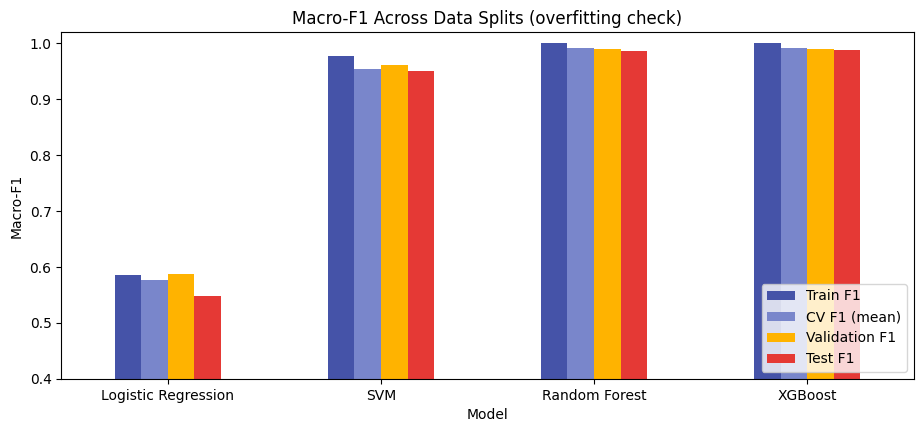

In [38]:
fit_table[["Train F1", "CV F1 (mean)", "Validation F1", "Test F1"]].plot(
    kind="bar", figsize=(11, 4.5), ylim=(0.4, 1.02),
    color=["#4553A8", "#7986CB", "#FFB300", "#E53935"])
plt.title("Macro-F1 Across Data Splits (overfitting check)")
plt.ylabel("Macro-F1"); plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()

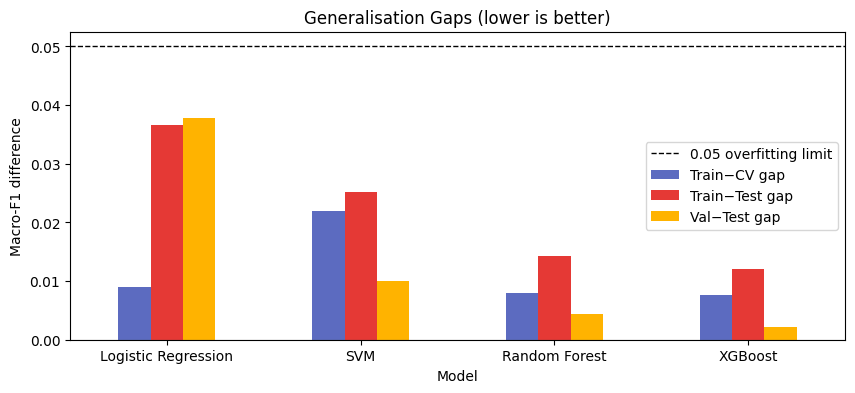

In [39]:
fit_table[["Train−CV gap", "Train−Test gap", "Val−Test gap"]].plot(
    kind="bar", figsize=(10, 4), color=["#5C6BC0", "#E53935", "#FFB300"])
plt.axhline(0.05, color="black", ls="--", lw=1, label="0.05 overfitting limit")
plt.axhline(0, color="grey", lw=0.8)
plt.title("Generalisation Gaps (lower is better)")
plt.ylabel("Macro-F1 difference"); plt.xticks(rotation=0); plt.legend(); plt.show()

**Learning curve helper**

In [42]:
def plot_learning_curve(name):
    sizes, train_sc, val_sc = learning_curve(
        models[name], X_train, y_train, cv=cv, scoring="f1_macro",
        train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
    tr_m, tr_s = train_sc.mean(1), train_sc.std(1)
    va_m, va_s = val_sc.mean(1), val_sc.std(1)
    plt.figure(figsize=(7, 4.5))
    plt.plot(sizes, tr_m, "o-", color="#4553A8", label="Training score")
    plt.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, color="#4553A8", alpha=0.15)
    plt.plot(sizes, va_m, "o-", color="#E53935", label="Cross-validation score")
    plt.fill_between(sizes, va_m - va_s, va_m + va_s, color="#E53935", alpha=0.15)
    plt.title(f"Learning Curve – {name}"); plt.xlabel("Training samples")
    plt.ylabel("Macro-F1"); plt.ylim(0.4, 1.02); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
    plt.show()
    print(f"Final gap (train − CV): {tr_m[-1] - va_m[-1]:.4f}")

**Learning curve – Logistic Regression**

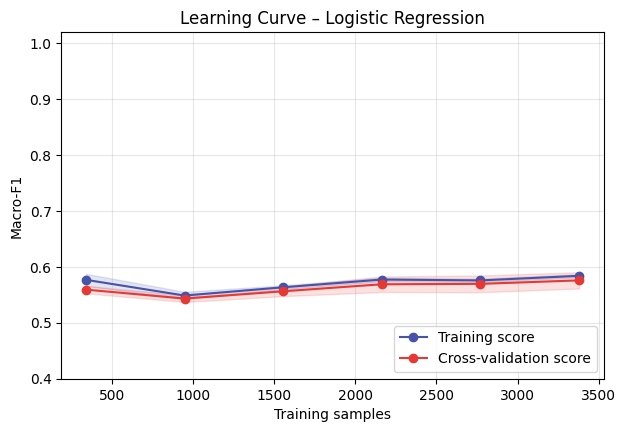

Final gap (train − CV): 0.0081


In [43]:
plot_learning_curve("Logistic Regression")

**Learning curve – SVM**

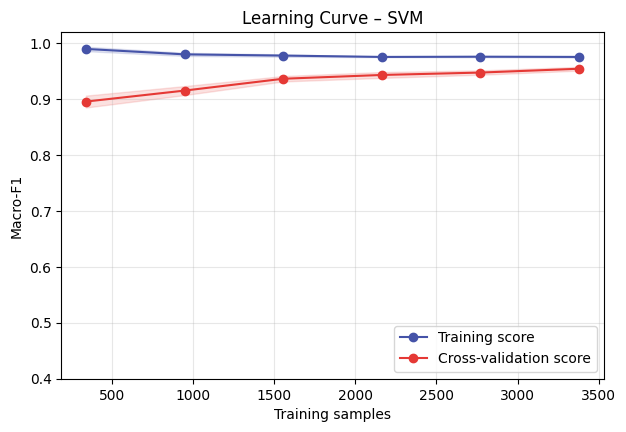

Final gap (train − CV): 0.0212


In [44]:
plot_learning_curve("SVM")

**Learning curve – Random Forest**

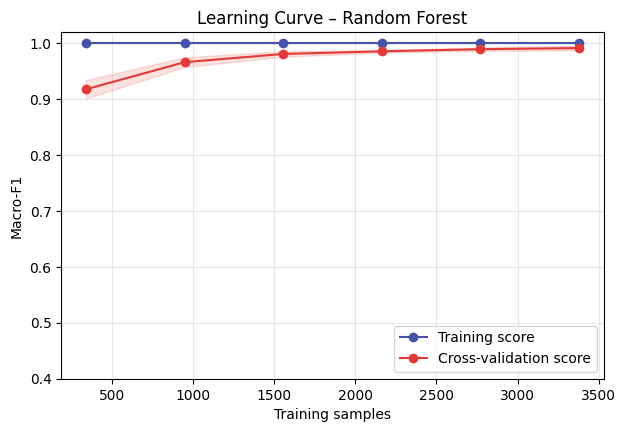

Final gap (train − CV): 0.0083


In [45]:
plot_learning_curve("Random Forest")

**Learning curve – XGBoost**

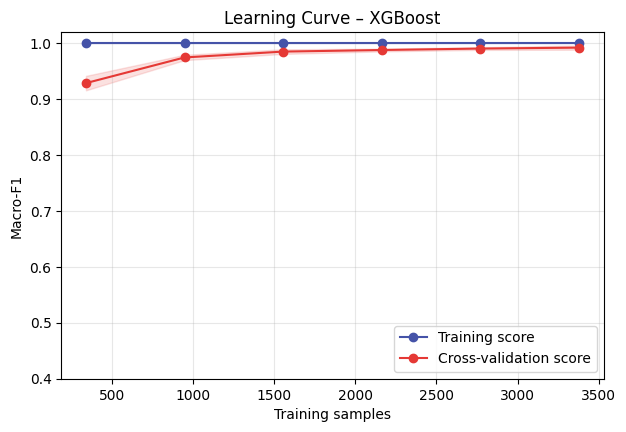

Final gap (train − CV): 0.0076


In [49]:
plot_learning_curve("XGBoost")